In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


RAIZ = Path.cwd().resolve()

if not (RAIZ / "laboratorio.py").exists():
    RAIZ = RAIZ.parent


PASTA_EXPERIMENTOS = (
    RAIZ
    / "resultados"
    / "experimento_final"
)


SEEDS_TREINO = {
    101, 102, 103,
    104, 105, 106
}

SEEDS_VALIDACAO = {
    107, 108, 109
}

SEEDS_TESTE = {
    110, 111, 112
}

In [2]:
def definir_split(seed):

    if seed in SEEDS_TREINO:
        return "treino"

    if seed in SEEDS_VALIDACAO:
        return "validacao"

    if seed in SEEDS_TESTE:
        return "teste"

    raise ValueError(
        f"Seed não prevista: {seed}"
    )

In [3]:
datasets = []


pastas = sorted(
    PASTA_EXPERIMENTOS.glob(
        "ensaio_seed_*"
    )
)


for pasta in pastas:

    with open(
        pasta / "ensaio.json",
        encoding="utf-8"
    ) as arquivo:

        meta = json.load(arquivo)


    seed = int(
        meta["config"]["seed"]
    )


    features = pd.read_csv(
        pasta / "features.csv"
    )

    avaliacao = pd.read_csv(
        pasta / "avaliacao.csv"
    )


    dados = features.merge(
        avaliacao,
        on="janela",
        validate="one_to_one"
    )


    dados["seed"] = seed

    dados["ensaio"] = (
        f"seed_{seed}"
    )

    dados["split"] = (
        definir_split(seed)
    )


    datasets.append(dados)


dataset = pd.concat(
    datasets,
    ignore_index=True
)


print(
    "Total de janelas:",
    len(dataset)
)

print(
    "Ensaios:",
    dataset["ensaio"].nunique()
)

display(
    dataset.head()
)

dataset["manutencao_legitima"] = 0

for pasta in pastas:

    with open(
        pasta / "ensaio.json",
        encoding="utf-8"
    ) as arquivo:

        meta = json.load(arquivo)


    seed = int(
        meta["config"]["seed"]
    )


    atividades = pd.read_csv(
        pasta
        / "atividades_legitimas.csv"
    )


    mascara_ensaio = (
        dataset["seed"] == seed
    )


    for _, atividade in atividades.iterrows():

        inicio = atividade["inicio"]
        fim = atividade["fim"]

        mascara_evento = (
            mascara_ensaio
            &
            (
                dataset["ts_inicio"]
                < fim
            )
            &
            (
                dataset["ts_inicio"]
                + dataset["duracao_s"]
                > inicio
            )
        )

        dataset.loc[
            mascara_evento,
            "manutencao_legitima"
        ] = 1

Total de janelas: 2160
Ensaios: 12


,janela,ts_inicio,duracao_s,taxa_requisicoes,bytes_rx,bytes_tx,latencia_ms,taxa_timeout,taxa_erro,consultas_cliente,latencia_disponivel,label,fase,seed,ensaio,split
0,0,1.793196e+09,1.0,1.0,12,13,0.84560,0.0,0.0,1,1,0,normal,101,seed_101,treino
1,1,1.793196e+09,1.0,2.0,24,26,1.98145,0.0,0.0,2,1,0,normal,101,seed_101,treino
2,2,1.793196e+09,1.0,0.0,0,0,NaN,NaN,NaN,0,0,0,normal,101,seed_101,treino
3,3,1.793196e+09,1.0,1.0,12,13,3.72480,0.0,0.0,1,1,0,normal,101,seed_101,treino
4,4,1.793196e+09,1.0,1.0,12,13,1.09110,0.0,0.0,1,1,0,normal,101,seed_101,treino


In [4]:
dataset["nivel_carga"] = "nenhuma"

for pasta in pastas:

    with open(
        pasta / "ensaio.json",
        encoding="utf-8"
    ) as arquivo:

        meta = json.load(arquivo)


    seed = int(
        meta["config"]["seed"]
    )


    ataques = pd.read_csv(
        pasta / "ataques.csv"
    )


    mascara_ensaio = (
        dataset["seed"] == seed
    )


    for _, ataque in ataques.iterrows():

        inicio = ataque["inicio"]
        fim = ataque["fim"]

        tipo = ataque["tipo"]

        nivel = tipo.replace(
            "carga_",
            ""
        )


        mascara_evento = (
            mascara_ensaio
            &
            (
                dataset["ts_inicio"]
                < fim
            )
            &
            (
                dataset["ts_inicio"]
                + dataset["duracao_s"]
                > inicio
            )
        )


        dataset.loc[
            mascara_evento,
            "nivel_carga"
        ] = nivel

In [5]:
dataset["condicao"] = "normal"


dataset.loc[
    dataset["fase"] == "recuperacao",
    "condicao"
] = "recuperacao"


dataset.loc[
    dataset["manutencao_legitima"] == 1,
    "condicao"
] = "manutencao"


dataset.loc[
    dataset["nivel_carga"] == "baixa",
    "condicao"
] = "carga_baixa"


dataset.loc[
    dataset["nivel_carga"] == "media",
    "condicao"
] = "carga_media"


dataset.loc[
    dataset["nivel_carga"] == "alta",
    "condicao"
] = "carga_alta"

distribuicao = pd.crosstab(
    dataset["split"],
    dataset["condicao"]
)

display(distribuicao)

display(
    dataset.groupby(
        ["split", "condicao"]
    )[
        "taxa_requisicoes"
    ]
    .agg([
        "count",
        "mean",
        "std",
        "min",
        "max"
    ])
    .round(3)
)

condicao,carga_alta,carga_baixa,carga_media,manutencao,normal,recuperacao
split,,,,,,
teste,63,60,60,45,135,177
treino,126,120,120,90,270,354
validacao,63,60,60,45,135,177


count    mean    std  min   max
split     condicao                                    
teste     carga_alta      63  10.540  2.184  1.0  12.0
          carga_baixa     60   2.983  0.390  2.0   4.0
          carga_media     60   5.983  0.390  5.0   7.0
          manutencao      45   4.911  0.900  2.0   6.0
          normal         135   1.022  0.311  0.0   2.0
          recuperacao    177   0.989  0.384  0.0   2.0
treino    carga_alta     126  10.524  2.131  1.0  12.0
          carga_baixa    120   3.000  0.535  2.0   4.0
          carga_media    120   5.975  0.354  5.0   7.0
          manutencao      90   4.833  0.939  0.0   6.0
          normal         270   1.019  0.460  0.0   2.0
          recuperacao    354   0.989  0.376  0.0   2.0
validacao carga_alta      63  10.508  2.162  1.0  12.0
          carga_baixa     60   3.017  0.469  2.0   4.0
          carga_media     60   6.000  0.319  5.0   7.0
          manutencao      45   4.933  0.720  3.0   6.0
          normal         135   1.030  0.385  0.0   2.0
          recuperacao    177   0.977  0.369  0.0   2.0

In [6]:
dataset["janela_transicao"] = 0

for ensaio, grupo in dataset.groupby(
    "ensaio"
):

    indices = grupo.sort_values(
        "janela"
    ).index

    condicoes = dataset.loc[
        indices,
        "condicao"
    ]

    mudou_anterior = (
        condicoes
        != condicoes.shift(1)
    )

    mudou_proxima = (
        condicoes
        != condicoes.shift(-1)
    )

    transicao = (
        mudou_anterior
        | mudou_proxima
    )

    dataset.loc[
        indices,
        "janela_transicao"
    ] = transicao.astype(int)

In [7]:
for split in [
    "treino",
    "validacao",
    "teste"
]:

    sementes = sorted(
        dataset.loc[
            dataset["split"] == split,
            "seed"
        ].unique()
    )

    print(
        split,
        sementes
    )

treino [np.int64(101), np.int64(102), np.int64(103), np.int64(104), np.int64(105), np.int64(106)]
validacao [np.int64(107), np.int64(108), np.int64(109)]
teste [np.int64(110), np.int64(111), np.int64(112)]


In [8]:
PASTA_DATASETS = (
    RAIZ
    / "datasets"
)

PASTA_DATASETS.mkdir(
    exist_ok=True
)

dataset.to_csv(
    PASTA_DATASETS
    / "dataset_experimental.csv",
    index=False
)

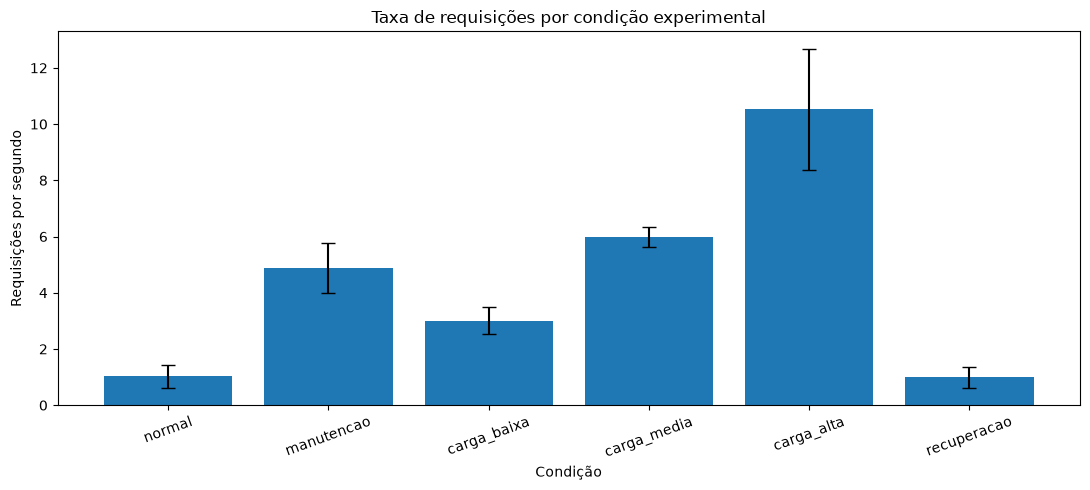

In [9]:
ordem = [
    "normal",
    "manutencao",
    "carga_baixa",
    "carga_media",
    "carga_alta",
    "recuperacao"
]


resumo = (
    dataset.groupby("condicao")[
        "taxa_requisicoes"
    ]
    .agg(
        media="mean",
        desvio="std"
    )
    .reindex(ordem)
)


fig, ax = plt.subplots(
    figsize=(11, 5)
)

ax.bar(
    resumo.index,
    resumo["media"],
    yerr=resumo["desvio"],
    capsize=5
)

ax.set_title(
    "Taxa de requisições por condição experimental"
)

ax.set_ylabel(
    "Requisições por segundo"
)

ax.set_xlabel(
    "Condição"
)

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()